# Anvendt KI og ML: Innsendingsoppgave – Bildeklassifisering- fasit
Velkommen til denne Jupyter notebooken, som du skal bruke til den andre obligatoriske innsendingsoppgaven i Høyskolen Kristianias emne «Anvendt kunstig intelligens og maskinlæring».

## Hvordan du bruker denne notebooken 
Du skal gå gjennom denne notebooken for å løse innsendingsoppgaven. Underveis skal du skrive kode som løser hver av de 13 kodeoppgavene skrevet _i kursiv_. Skriv kode inn i kodecellen rett under oppgaven, og legg gjerne til flere kodeceller. Du kan finne og gjenbruke relevant kode i andre notebooks i emnet. Du kan eventuelt bruke andre programmeringsspråk etter avtale med veilederen din, men alle kodehint er gitt for Python.

Underveis vil du også finne 11 fritekstoppgaver du må besvare tekstlig. Også disse er skrevet _i kursiv_. De skal besvares i markdowncellene rett under oppgavene. Referer til egen kode der det er relevant.

Hvis du står fast, kontakt veilederen din for å få hjelp til å komme videre (via «Innboks» i hovedmenyen i Canvas, _ikke_ klikk «Lever oppgave»).

Etter at du har lagt inn egen tekst og kode for hver oppgave, skal du levere inn en PDF-versjon av denne notebooken. PDF-en skal vise både den skriftlige besvarelsen din og output fra alle kodecellene. Du eksporterer notebooken fra JupyterLab via File-menyen -> Print... I utskriftvinduet velger du «Lagre som PDF» i feltet Destinasjon.

## Problemstilling: Klassifisere bilder som enten teddybjørner eller isbjørner
Oppgaven går ut på å lage en modell som kan klassifisere om bilder tilhører enten kategorien «isbjørn» eller kategorien «teddybjørn». Vi skal teste flere modeller og se hvilken som fungerer best.

In [1]:
#!pip install efficientnet

In [2]:
#Alle nødvendig pakker du trenger for å løse oppgavene i eksamensheftet
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout, GlobalMaxPooling2D, BatchNormalization  
from tensorflow.keras.initializers import glorot_normal
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.optimizers import Adam

from efficientnet import tfkeras as efficientnet

from oblig2_functions import (read_images, plot_history, plot_cm, plot_losses, predict_labels, 
                            print_classification_report, set_seed,
                            plot_predicted, show_explanation)

In [3]:
# Hvis du mangler cv2 pakken kan du installere den med:
# (Må kun kjøres én gang)
#!pip install opencv-python

In [4]:
seed = set_seed()

# Tren en modell for å gjøre klassifisiering mellom teddybjørner og isbjørner. 

Folderen 'Images' inneholder en rekke bilder av isbjørner og teddybjørner. Oppgaven går ut på å lage en modell som kan klassifisere om bilder tilhører den ene eller den andre kategori. Oppgaven besvares via spørsmål 1-8.

## 1. Datapreparering

### 1.1. Les inn data

In [5]:
img_polar = read_images('./bilder/data1/polar')
img_teddy = read_images('./bilder/data1/teddy')

### 1.2. Visualisering av data

Vis noen bilder for å forstå hvordan data er bygget opp.

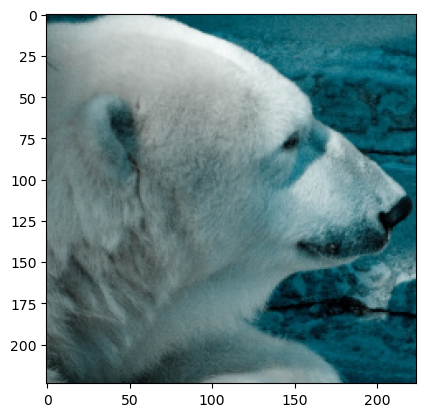

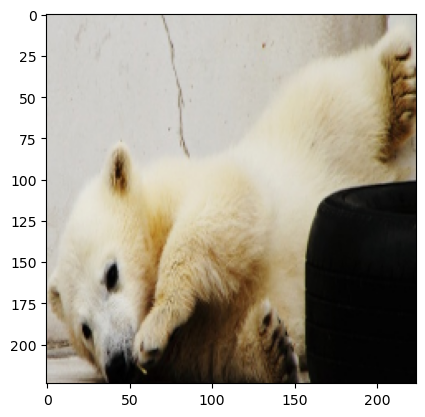

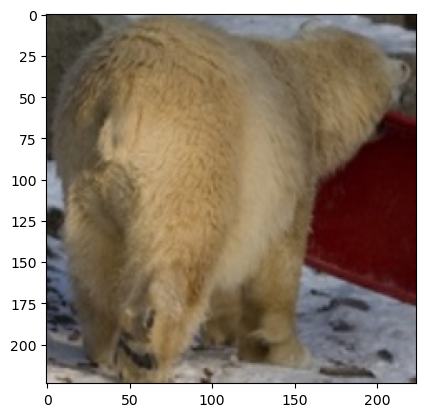

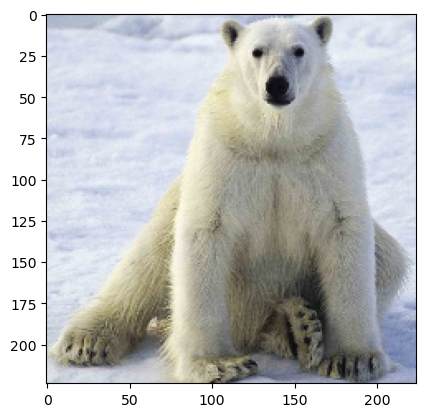

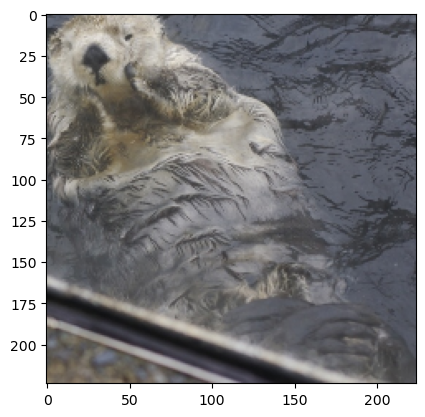

...

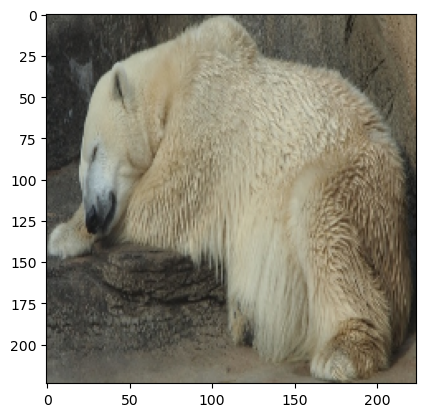

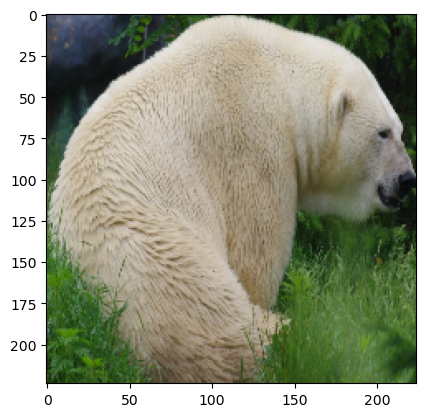

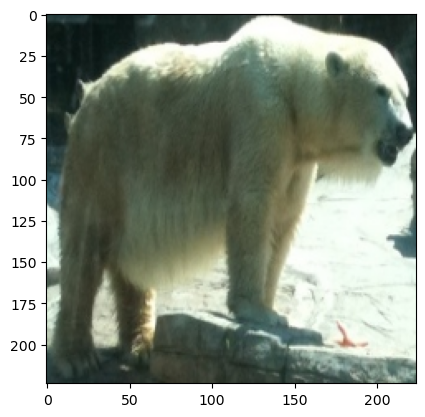

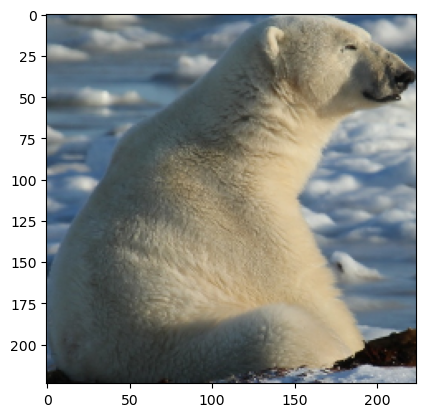

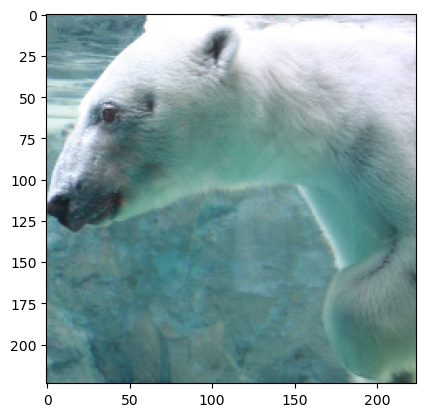

In [6]:
for img in img_polar[:20]:
    plt.imshow(img)
    plt.show()

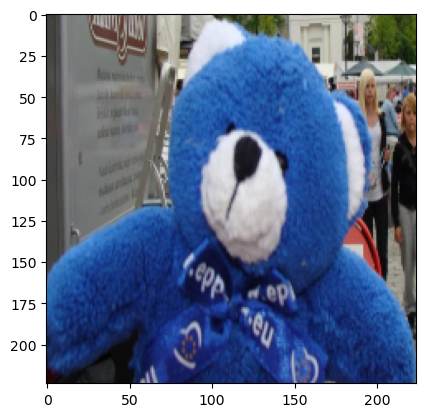

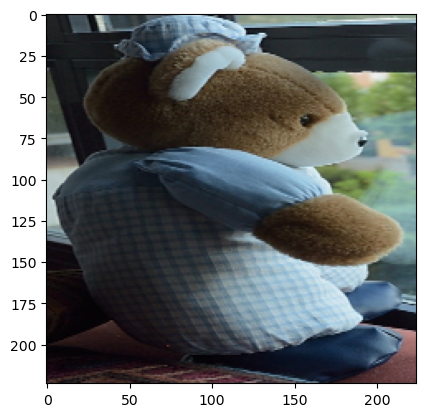

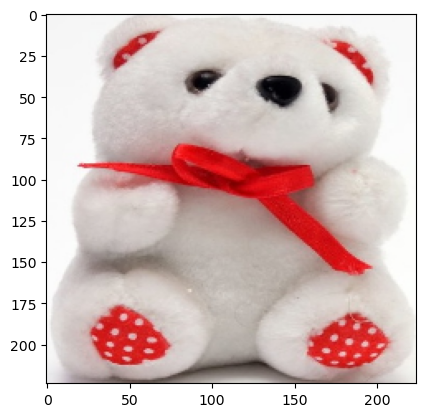

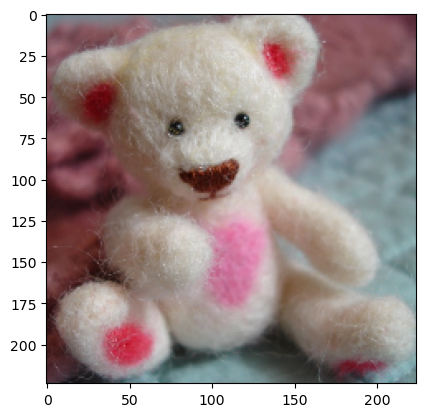

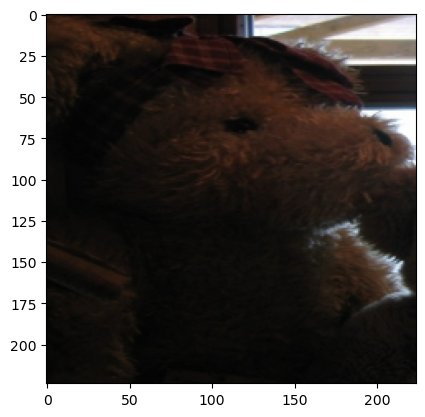

...

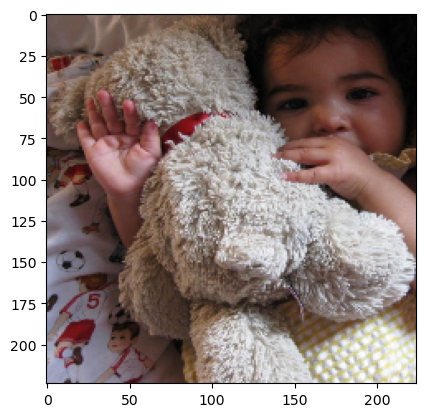

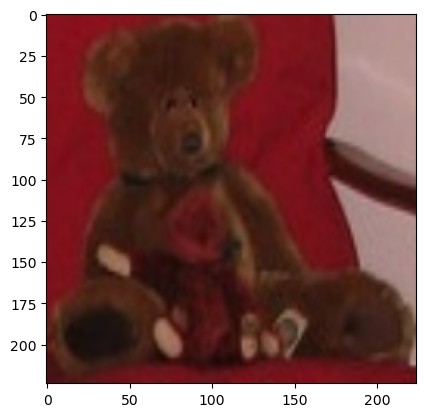

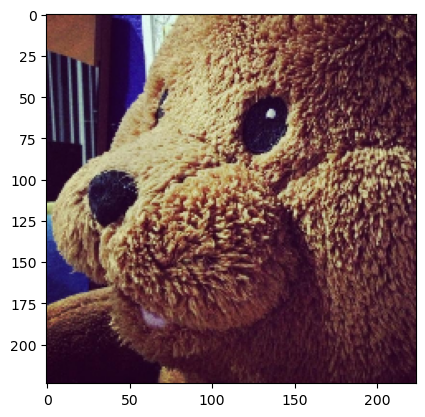

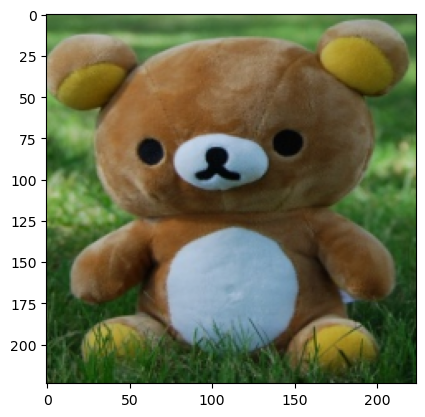

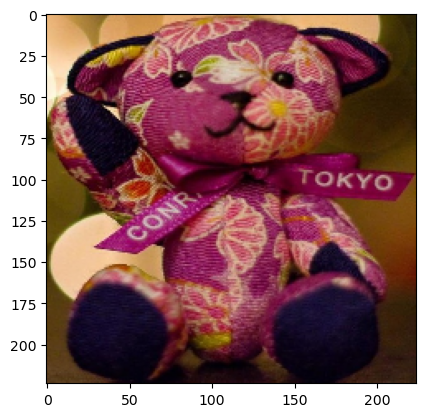

In [7]:
for img in img_teddy[:20]:
    plt.imshow(img)
    plt.show()

**Kodeoppgave 1**:_
- _Få en rask oversikt over datasettet: Hvor mange bilder er klassifisert som isbjørner, og hvor mange er klassifisert som teddybjørner?_

In [8]:
# KODEOPPGAVE 1

# Din kode under her:
len(img_polar), len(img_teddy)

(212, 29)

### 1.3. Merk hvert bilde som tilhørende kategori 0 eller 1

In [9]:
# Først lager vi en dictionary som forteller at isbjørner er klasse 0 og teddybjørner er klasse 1:
class_dict = dict({
    0: 'polar',
    1: 'teddy'
})

# Vi lager lister over klasse-verdier og klasse-navner til senere bruk
label_bool = list(class_dict.keys())
label_names = list(class_dict.values())

class_dict

{0: 'polar', 1: 'teddy'}

In [10]:
# Legger sammen bilder av isbjørner og teddyrbjørner
img_all = np.concatenate([img_polar, img_teddy])

In [11]:
# Vi trenger også arrays med label-verdier. Disse lager vi med np.zeros and np.ones. 
# Her er det lurt å dobbeltsjekke at verdiene er de samme som i dictionary.

labels_polar = np.zeros(len(img_polar)) # Opprett array med null for alle bilder i img_polar
labels_teddy = np.ones(len(img_teddy)) # Opprett array med én for alle bilder i img_teddy
labels_all = np.concatenate([labels_polar, labels_teddy]) # Legg alle labels sammen i ett array

### 1.4 Splitt data i trening-, validering- og testdata

**Kodeoppgave 2: Splitt data**

Splitt data i treningsdata (64%), valideringdata (16%) og testdata (20%) ved å bruke funksjonen `train_test_split()`.

De nye variablene skal hete henholdsvis: X_train, y_train, X_val, y_val, X_test og y_test. 

**Hint**: Bruk `train_test_split()` **to** ganger for å få tre disjunkte datasett. Sett argumentene `test_size` og `random_state` som `test_size=0.2` og `random_state=seed` **begge ganger**.

In [12]:
# KODEOPPGAVE 2

#Din kode under her:

#split all the data into training and test
X_training, X_test, y_training, y_test = train_test_split(img_all, labels_all, test_size=0.2, random_state=seed)
#split training data into training and validation
X_train, X_val, y_train, y_val = train_test_split(X_training, y_training, test_size=0.2, random_state=seed)

**Kodeoppgave 3: Normalisering**

Vi ønsker å normalisere dataene slik at hver pixel i bilde får en verdi mellom 0 og 1. 
Ettersom bilder per definisjon består av tre kanaler med pixel-verdier mellom 0 og 255 er det enkelt å normalisere ved å dele alle verdier på 255, for eksempel: `X = X/255`

De nye variablene skal også hete: X_train, X_val og X_test.

In [13]:
# KODEOPPGAVE 3

#Din kode under her: 
X_train, X_val, X_test = X_train/255, X_val/255, X_test/255

## 2. Model 1: Første modell

In [14]:
# Først lager vi en funksjon som genererer et nevralt nettverk. Her trenger du ikke endre noe.
# Funksjonen kan gi noen varsler om bruk av CPU. Disse kan ignoreres.

def create_model():
    """
    Defines the neural network.
    We will be using the same model over the assignment, so we will define it here for consistency.
    """
    
    seed = set_seed()
    
    model = Sequential()
    model.add(Conv2D(32,3,padding="same", activation="relu", input_shape=(224,224,3)))
    model.add(MaxPool2D())

    model.add(Conv2D(32, 3, padding="same", activation="relu"))
    model.add(MaxPool2D())

    model.add(Conv2D(64, 3, padding="same", activation="relu"))
    model.add(MaxPool2D())
    model.add(Dropout(0.4, seed=seed))

    model.add(Flatten())
    model.add(Dense(128,activation="relu", kernel_initializer=glorot_normal(seed=seed)))
    model.add(Dense(2, activation="softmax", kernel_initializer=glorot_normal(seed=seed)))
    
    opt = Adam(learning_rate=0.0001)
    model.compile(optimizer=opt, loss=SparseCategoricalCrossentropy(), 
                  metrics=['accuracy'])

    
    return model


In [15]:
model_1 = create_model()

**Kodeoppgave 4: Modellinformasjon**

Bruk summary() fra klassen `tenforflow.keras.Model()` til å få mer innsikt i modellen. Rapporter antall konvolusjonslag (convolutional layers) og trenbare parametere (trainable parameters).

In [16]:
# KODEOPPGAVE 4

#Din kode under her:
model_1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 224, 224, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 112, 112, 32)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 112, 112, 32)      9248      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 56, 56, 32)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 56, 56, 64)        18496     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 28, 28, 64)       0

_**Fritekstoppgave**:_

1. _Rapporter antall konvolusjonslag (convolutional layers) og trenbare parametere (trainable parameters)._

**Svar**:

Antall konvolusjonslag (convolutional layers): 3
Antall trenbare parametere (trainable parameters): 6 451 554

### 2.1. Trene modell 1

For å trene modellen må vi definere antall epoker. Vi plotter trening og validerings-loss mens vi trener og lagrer i tillegg treningshistorien for senere bruk.

Treningen kan ta et par minutter.

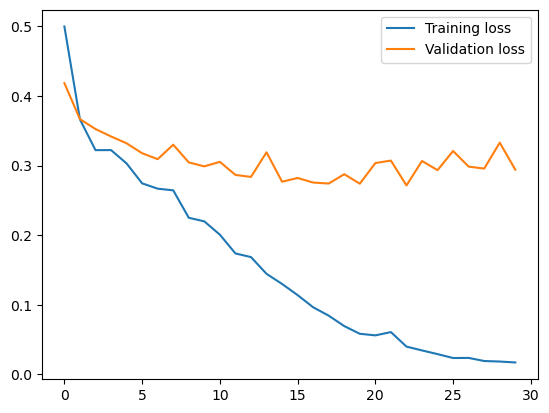

5/5 [==============================] - 8s 2s/step - loss: 0.0173 - accuracy: 0.9935 - val_loss: 0.2940 - val_accuracy: 0.8974


In [17]:
n_epochs = 30
history_1 = model_1.fit(X_train, y_train, epochs=n_epochs, validation_data=(X_val, y_val), callbacks=[plot_losses])

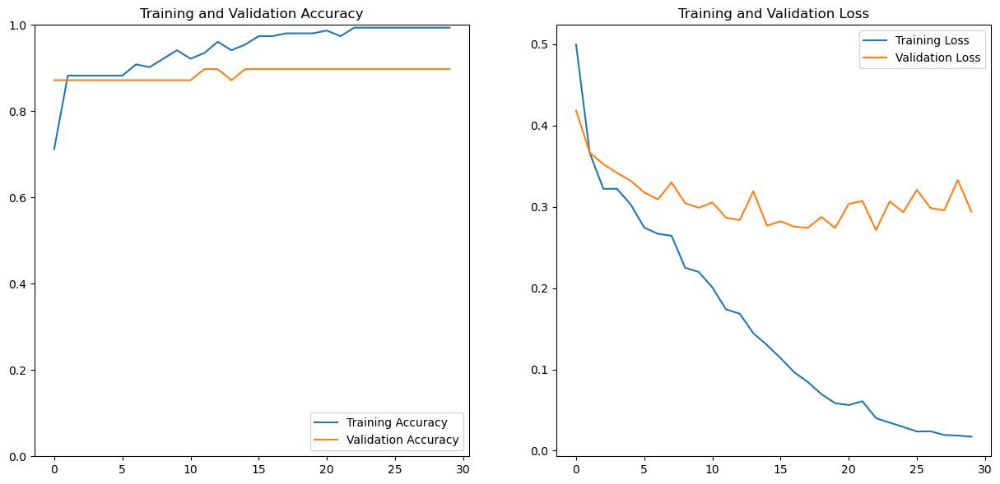

In [18]:
plot_history(history_1)

**Bonusinformasjon:**

(Du kan springe over dette)

Når modellen er trent kan du lagre vektene slik at du kan bruke modellen igjen uten å trene den. I stedet kan du neste gang opprette modellen og loade tidligere lagret vekte.

In [19]:
# Fjern kommentarer og kjør linjen du vil bruke:
# Lagre vektene i mappen `./models` under navnet `model_1`.  
#model_1.save_weights('./models/model_1')

# Last inn vektene i den kompilerte modellen
#model_1.load_weights('./models/model_1')

### 2.2. Evaluering av modell 1

For å vurdere brukbarheten av modellen må vi evaluere den. Vi starter med å se på confusion matrix.

In [20]:
# Først predikerer vi på testsettet
predictions = predict_labels(X_test, model_1)

2/2 [==============================] - 1s 142ms/step


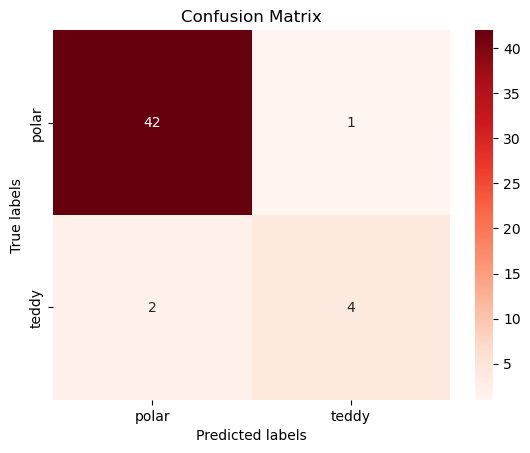

In [21]:
# Plot forvirringsmatrisen
cm = confusion_matrix(y_test, predictions, labels=label_bool)
plot_cm(cm, label_names)

In [22]:
# Vi kan også printe klassifiseringsrapporten
print_classification_report(y=y_test, y_pred=predictions, label_names=label_names)

              precision    recall  f1-score   support

       polar       0.95      0.98      0.97        43
       teddy       0.80      0.67      0.73         6

    accuracy                           0.94        49


**Kodeoppgave 5: Evaluer modellen**

Du trenger ikke skrive kode. Lim inn forvirringsmatrisen (confusion matrix) og klassifiseringsrapporten. 

**Fritektoppgave:**

2. Bruk dette til å rapportere følgende:
* Det totale antall isbjørner i testdata
* Det totale antall teddybjørner i testdata
* Antall korrekt klassifiserte isbjørnebilder
* Antall korrekt klassifiserte teddybjørnebilder
* Antall feil klassifiserte isbjørnebilder
* Antall feil klassifiserte teddybjørnebilder

**Svar**

* Totalt antall isbjørner i testdataene: 43
* Totalt antall teddybjørner i testdataene: 6
* Antall korrekt klassifiserte isbjørnbilder: 42
* Antall korrekt klassifiserte teddybjørnbilder: 2
* Antall feil klassifiserte isbjørnbilder: 1
* Antall feil klassifiserte teddybjørnbilder: 4

## 3. Datapreparering - Legg til mer data

De fleste modeller kan forbedres med mer data. Vi legger nå til fler bilder med teddybjørner og lager en ny modell.

In [24]:
img_teddy2 = read_images('./bilder/data2/teddy')

In [25]:
img_all2 = np.concatenate([img_all, img_teddy2])

**Kodeoppgave 5: Nye labels**
    
Lag et nytt array med labels for de nye teddybjørnene (slik vi gjorde i oppgave 2).
Navnet må være labels_teddy2. Bruk funksjonen np.concatenate() til å tilføye det nye arrayet på slutten av arrayet med alle tidligere labels. Navnet på det nye arrayet skal være labels_all2.


In [ ]:
# KODEOPPGAVE 6

# Din kode under her:

#labels_teddy2 = 
#labels_all2 =

labels_teddy2 = np.ones(len(img_teddy2))
labels_all2 = np.concatenate([labels_all, labels_teddy2])

NameError: name 'np' is not defined

**Kodeoppgave 6: Antall bilder**

Rapporter antall bilder med isbjørner og teddybjørner etter vi har lagt til flere teddybjørner.

In [27]:
# KODEOPPGAVE 7

# Din kode under her:
len(labels_polar), len(labels_teddy2) + len(labels_teddy)

(212, 117)

**Kodeoppgave 7: Splitt data**

Gjenta prosessen fra kodeoppgave 2 og split data i nye trenings-, validerings- og testset.

Gjenbruk koden fra kodeoppgave 2 til å splitte data men husk å endre på variabelnavnene slik at du splitter ny data .

In [28]:
# KODEOPPGAVE

#Din kode under her:
X_training, X_test, y_training, y_test = train_test_split(img_all2, labels_all2, test_size=0.2, random_state=seed) 
X_train, X_val, y_train, y_val = train_test_split(X_training, y_training, test_size=0.2, random_state=seed) 

Kodeoppgave: Normaliser data

Gjenta prosessen fra kodeoppgave 3 og normaliser data.

In [29]:
# KODEOPPGAVE

#Din kode under her:
X_train, X_val, X_test = X_train/255, X_val/255, X_test/255

## 4. Model 2: Tren ny modell

In [30]:
# Først bruker vi create_model-funksjonen til å opprette en ny modell
model_2 = create_model()

**Kodeoppgave 8: Fit modellen**

Fit `model_2` til de nye dataene. Tren i nøyaktig **30 epoker**.

**NB!** Hvis du eksekverer `model_2.fit()` mer enn en gang etter kompilering (opprettelse) fortsetter den hvor forrige trening sluttet og trener dermed flere epoker. 

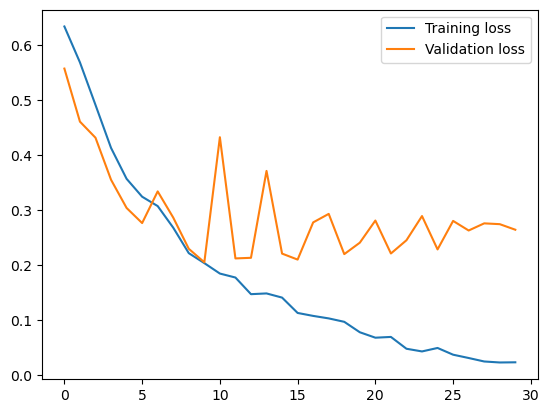

7/7 [==============================] - 9s 1s/step - loss: 0.0238 - accuracy: 1.0000 - val_loss: 0.2644 - val_accuracy: 0.9245


In [31]:
# KODEOPPGAVE 8

# Din kode under her

history_2 = model_2.fit(X_train, y_train, epochs=30, validation_data=(X_val, y_val), callbacks=[plot_losses])

In [32]:
# Se bonusinfo om lagrede modeller over

# Lagre vektene i mappen `./models` under navnet `model_2`. 
#model_2.save_weights('./models/model_2')

# Last inn vektene i den kompilerte modellen
#model_2.load_weights('./models/model_2')

### 4.2. Evaluering av modell 2

**Kodeoppgave 9: Evaluer modellen 2**

Evaluer `model_2` på testdata og lim inn forvirringsmatrisen (confusion matrix) som for `model_1`. Husk at du må starte med å gjøre en prediksjon på de nye testdataene.

3/3 [==============================] - 1s 153ms/step


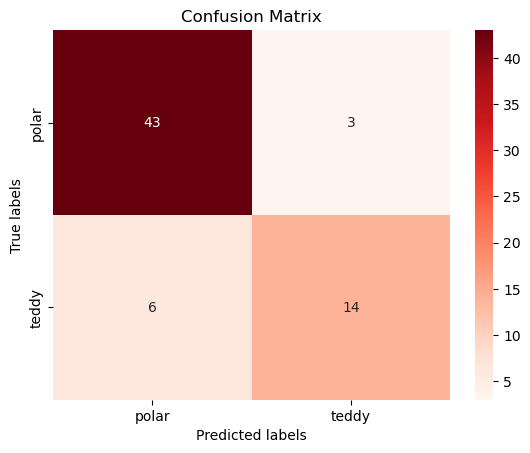

In [33]:
# KODEOPPGAVE 9

# Din kode under her

predictions = predict_labels(X_test, model_2)
cm = confusion_matrix(y_test, predictions, labels=label_bool)
plot_cm(cm, label_names)

In [34]:
print_classification_report(y=y_test, y_pred=predictions, label_names=label_names)

              precision    recall  f1-score   support

       polar       0.88      0.93      0.91        46
       teddy       0.82      0.70      0.76        20

    accuracy                           0.86        66


_**Fritekstoppgaver**:_

3. _Hva kan du si om balansen/ubalansen (class imbalance) i datasettet som brukes til å trene modell 1 og modell 2? Er det en av klassene som dominerer, og i så fall hvilken? Er det en av modellene som har mer balanserte data?_

4. _Hvordan påvirker denne balansen/ubalansen modellens prediksjon for hver av klassene? Hvis data er ubalanserte, er det da noe spesielt du kan risikere at modellen lærer å predikere – og i så fall hva?_

5. _Bias-varians-avveining er en avveining mellom modellens evne til å generalisere og evnen til å forklare sammenhenger i dataene, jf. figuren nedenfor. Forklar hvordan vi forventer at treningstap/treningsfeil og valideringstap/valideringsfeil (training error og validation error) endrer seg når vi trener algoritmen. Si noe om følgende:_
    - _Forventer vi høye eller lave tapsverdier/feilverdier på trenings- og valideringsdata i starten av treningen?_
    - _Hva skjer når vi trener modellen over lang tid?_
    - _Når bør vi stoppe å trene, og hvorfor?_
    - _Hvilket tap (dvs. hvilke feilverdier) forventer vi å finne for trenings- og validerings-data hvis vi har en modell som fanger opp all variansen i treningsdataene?_

![Bias-varians-avveining (Kilde: LearnOpenCV)](./figures/bias-varians-oblig2.png)
 (Kilde: LearnOpenCV)

6. _Forklar prosessen med kryssvalidering. Hvilken del av koden for modell 2 ville du ha endret hvis du skulle bruke kryssvalidering? Hvordan er kryssvalidering forskjellig fra enkel oppsplitting i treningsdata, valideringsdata og testdata? Hvilken av disse metodene bør vi stole mest på når vi skal fintune modellen?_

7. _Bruk metrikkene nøyaktighet (accuracy), presisjon (precision) og sensitivitet (recall) til å evaluere modell 1 og modell 2. Forklar hva hver av disse metrikkene sier om modellenes faktiske ytelse for hver klasse. Hvordan vil balansen/ubalansen i klassene påvirke evalueringen?_

**Svar**

3. Balansert/ubalansert datasett (class imbalance)
    
    Stor ubalanse; isbjørn (polar bears) er den dominerende klassen; 
    Modell 2 er trent på mer balanserte data enn modell 1; 
4. Modellen fungerer bedre på majoritetsklassen, dvs. isbjørner / polar bears;
    
    Og dårligere på minoritetsklassen, dvs. teddybjørner / teddy bears (trenger ikke nevne begge deler); 
    Modellen kan lære å alltid predikere majoritetsklassen eller ha bias for majoritetsklassen (trenger ikke nevne begge deler)
5. Bias-varians-avveining (bias-variance tradeoff)
    
    Vi forventer høye tapsverdier både på trenings- og valideringsdata (high training error and high validation error) i starten av treningen.
    Etter lang trening vil treningstapet være lavt, mens valideringstapet kan øke eller bli værende høyere.
    Treningen bør stoppes når både trenings- og valideringstapet er lavt, eller før valideringstapsfunksjonen øker.
    En modell som fanger all varians i treningsdataene, kan forventes å ha lavt treningstap og høyt valideringstap (men det kan være lavt valideringstap i veldig rene data).
6. Kryssvalidering
    
    Vi splitter treningsdataene i trenings- og valideringsdata flere ganger, og hver splitt bruker forskjellige deler av dataene.
    For å bruke kryssvalidering på innsendingsoppgaven, må man endre koden der treningsdata splittes i trenings- og valideringssett, og så bruke disse settene når man skal gjennomføre en fit av modellen.
    Med enkel oppsplitting blir dataene kun splittet én gang, mens med kryssvalidering blir de delt opp flere ganger.
    Kryssvalidering er en grundigere (og sånn sett «bedre») metode for å fintune modellen.
7. Evalueringsmetrikker
    
    Oppgir korrekte tallene for alle tre metrikkene på begge modellene.
    Forklaring av hvordan de tallene skal tolkes.
    Klasse-ubalansen i testdataene fører til at nøyaktigheten fremstår høyere enn den reelt sett er.
    

## 5. Bruk av overføringslæring til å lage modell 3

Modellen i `model_create()` er ganske simpel. I stedet ønsker vi å forbedre klassifiseringen ved å bruke en mer komplisert modell som allerede er pre-trent på å klassifesere andre typer bilder. Vi bruker modell-typen EfficientNetB0 som kan kalles direkte fra keras. Første gang du kaller modellen lastes vektene ned. Dvs. du må ha tilgang på internett.

In [35]:
# Koden her laster inn ferdigtrent modell og legger til egne lag for å kunne tilpasse seg vårt klassifiseringsproblem:
seed = set_seed()

input_shape = (224,224,3)
nr_outputs = 2
base_model = efficientnet.EfficientNetB0(weights="imagenet", include_top=False, input_shape=input_shape)
base_model.trainable = False

model_3 = Sequential()
model_3.add(base_model)
model_3.add(GlobalMaxPooling2D())
model_3.add(Dense(nr_outputs, activation="softmax", kernel_initializer=glorot_normal(seed=seed)))

opt = Adam(learning_rate=0.0001)
model_3.compile(optimizer=opt, loss=SparseCategoricalCrossentropy(), metrics=["accuracy"])

_**Fritekstoppgaver**:_

8. _Forklar kort hva disse to delene av koden gjør:_
    - `base_model.trainable = False`
    - `include_top=False`

9. _Forklar formålet og prosessen med overføringslæring. På hvilken måte er overføringslæring gunstig for trening av en modell til en ny oppgave? På hvilken måte må arkitekturen til den overførte modellen tilpasses? Hva betyr det å fryse lag, og hvorfor gjør vi det?_

**Svar:**

8. «base_model.trainable = False» fryser lagene.
    «include_top=False» kutter vekk topplaget på det nevrale nettverket.
9. Overføringslæring
    
    Formålet er å forbedre ytelsen ved å bruke ferdigtrente modeller (lag og vekter) for å unngå å lære unødvendig mye fra bunnen av (f.eks. å gjenkjenne kanter, former og farger), men heller bruke ressursene på å lære selve hovedoppgaven (f.eks. klassifisering).
    Prosessen er å laste inn en dyplæringsmodell med gitte lag og ferdigtrente vekter, fjerne siste lag, og legge til nye lag som er tilpasset oppgaven.
    Å fryse lag innebærer at vektene i disse lagene ikke blir oppdatert under trening (de er ikke trenbare).

### 5.1. Trening av modell 3

**Kodeoppgave 10: Tren modell 3**

Fit `model_3` til de nye data. Tren i presis **30 epoker**. 

**NB!** Hvis du eksekverer `model_3.fit()` mer enn en gang etter kompilering (opprettelse) fortsetter den hvor forrige trening sluttet og trener dermed flere epoker. 

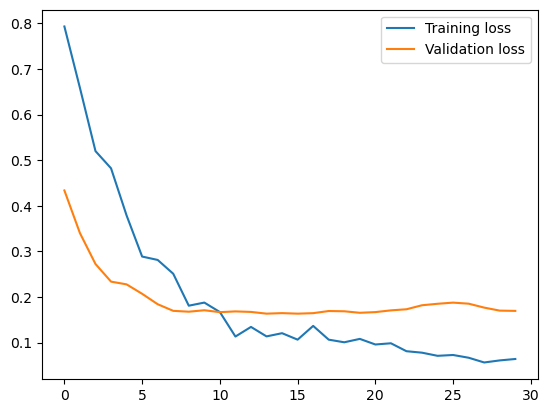

7/7 [==============================] - 12s 2s/step - loss: 0.0640 - accuracy: 0.9857 - val_loss: 0.1695 - val_accuracy: 0.9623


In [36]:
# KODEOPPGAVE

# Din kode under her

history = model_3.fit(X_train, y_train, epochs=30, validation_data=(X_val,y_val), callbacks=[plot_losses])

In [37]:
# Lagre vektene i mappen `./models` under navnet `model_3`. 
#model_3.save_weights('./models/model_3')

# Last inn vektene i den kompilerte modellen
#model_3.load_weights('./models/model_3')

### 5.2. Evaluering av modell 3

**Kodeoppgave 11: Evaluer modellen 3**

Evaluer `model_3` på test data og plot forvirringsmatrisen som for `model_1` og `model_2`. Husk at du må starte med å gjøre en prediksjon på de nye test data.


3/3 [==============================] - 5s 749ms/step


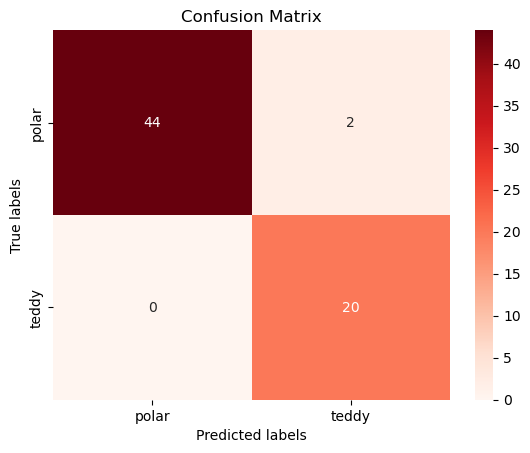

In [38]:
# KODEOPPGAVE

# Din kode under her

predictions = predict_labels(X_test, model_3)
cm = confusion_matrix(y_test, predictions, labels=label_bool)
plot_cm(cm, label_names)

In [39]:
print_classification_report(y=y_test, y_pred=predictions, label_names=label_names)

              precision    recall  f1-score   support

       polar       1.00      0.96      0.98        46
       teddy       0.91      1.00      0.95        20

    accuracy                           0.97        66


## 6. Evaluering av modellene ved å se på ukorrekte prediksjoner

Vi evaluerer de tre modeller mot hverandre ved å sammenligne klassifiseringsrapportene.

**Note**: Here, we evaluate all the models on the test data which was a part of the data including additional teddy bear images. Since we train `model_1` on a different data split, we are likely introducing data leakage (some of these test data were used in the training). This is a bad practice, which results in an overly positive evaluation of the model (since some test samples were seen by it in the training). We neglect this fact, since `model_1` still has the worst performance.

In [40]:
# Prediksjoner fra alle tre modeller på test data:
predictions_1 = predict_labels(X_test, model_1)
predictions_2 = predict_labels(X_test, model_2)
predictions_3 = predict_labels(X_test, model_3)

3/3 [==============================] - 3s 771ms/step


In [41]:
print_classification_report(y=y_test, y_pred=predictions_1, label_names=label_names)

              precision    recall  f1-score   support

       polar       0.84      1.00      0.91        46
       teddy       1.00      0.55      0.71        20

    accuracy                           0.86        66


In [42]:
print_classification_report(y=y_test, y_pred=predictions_2, label_names=label_names)

              precision    recall  f1-score   support

       polar       0.88      0.93      0.91        46
       teddy       0.82      0.70      0.76        20

    accuracy                           0.86        66


In [43]:
print_classification_report(y=y_test, y_pred=predictions_3, label_names=label_names)

              precision    recall  f1-score   support

       polar       1.00      0.96      0.98        46
       teddy       0.91      1.00      0.95        20

    accuracy                           0.97        66


**Kodeoppgave 12: Inspiser klassifiseringseksempler**

Basert på eksempelet fra modell 1 skal du vise bilder for feilklassifiseringer fra modell 2 og 3. For hver modell skal du vise eksempelbilder hvor teddybjørner er predikert som isbjørner og hvor isbjørner er feilklassifisert som teddybjørner (fem felter med kode).

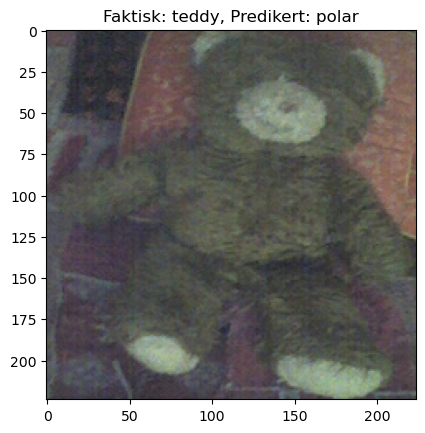

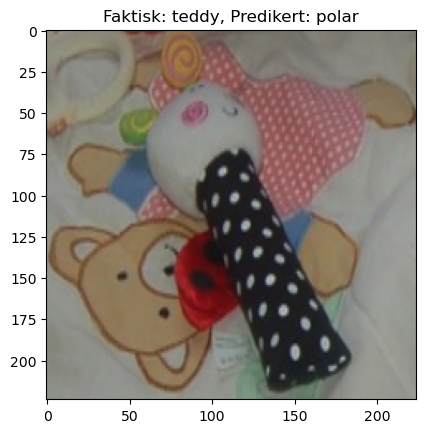

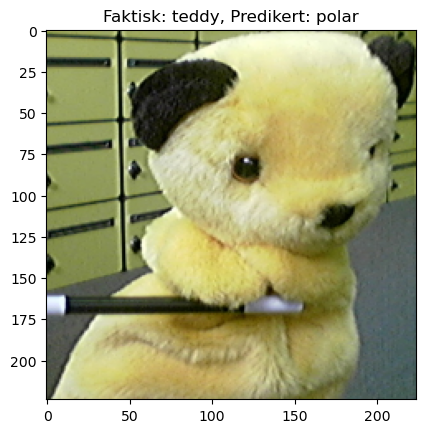

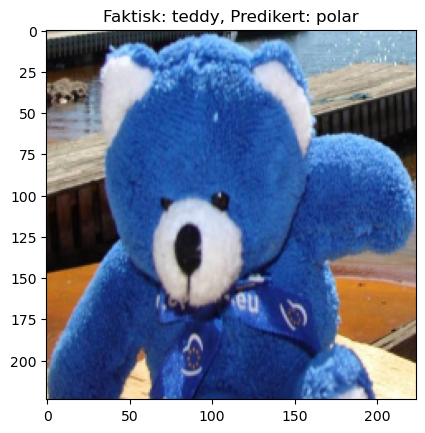

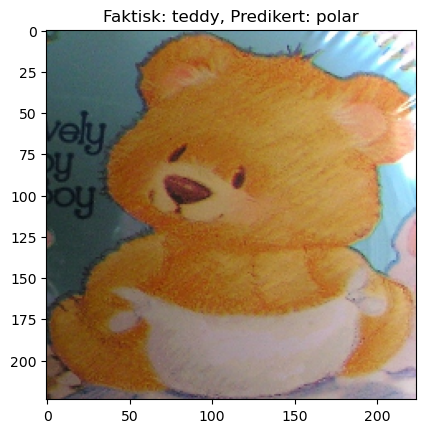

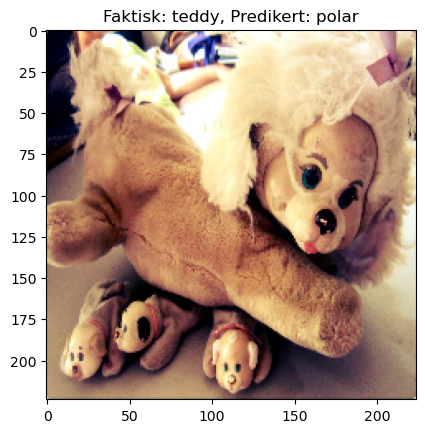

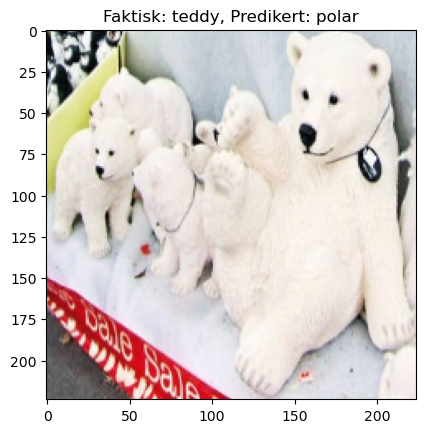

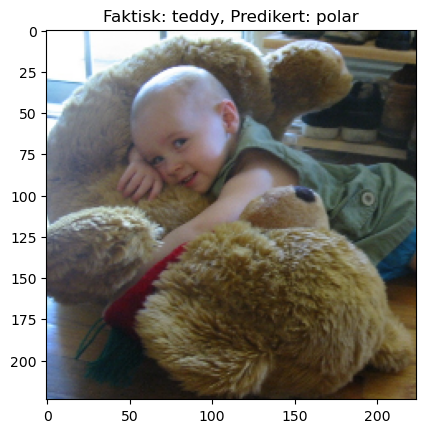

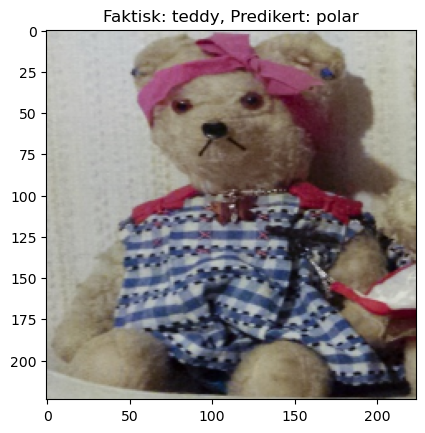

In [44]:
# Modell 1, bilder av teddybjørner klassifisert som isbjørn i modell 1:
plot_predicted(y = y_test, y_pred = predictions_1, X=X_test, real_class=1, pred_class=0, 
               class_dict=class_dict, nr_pic=10)

In [45]:
# KODEOPPGAVE 11

# Modell 1, bilder av isbjørner klassifisert som teddybjørn i modell 1:

# Din kode under her:
plot_predicted(y = y_test, y_pred = predictions_1, X=X_test, real_class=0, pred_class=1, 
               class_dict=class_dict, nr_pic=10)

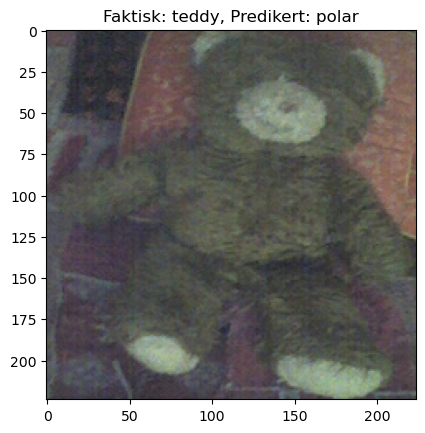

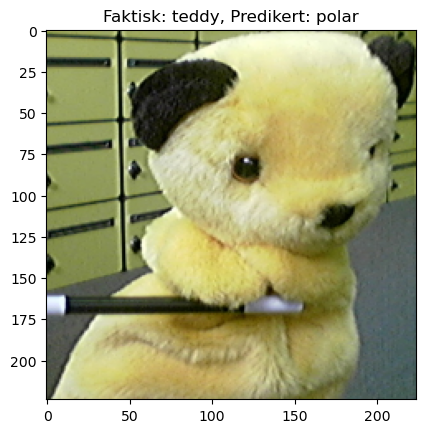

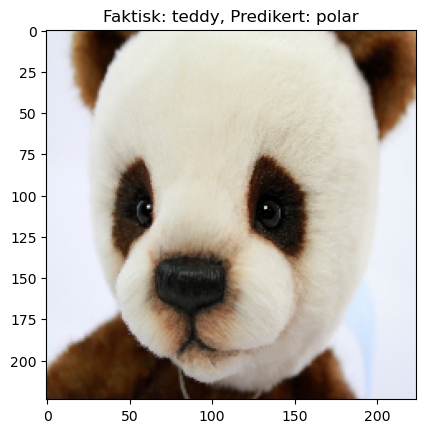

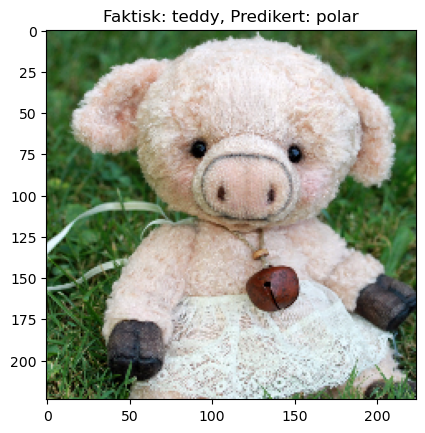

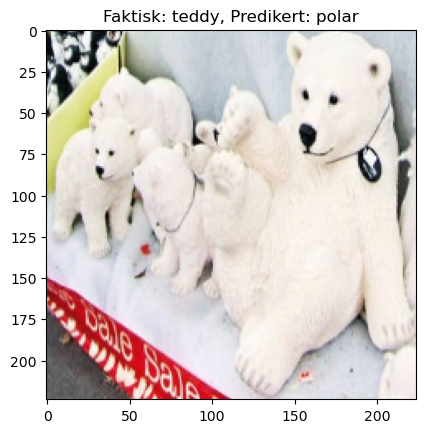

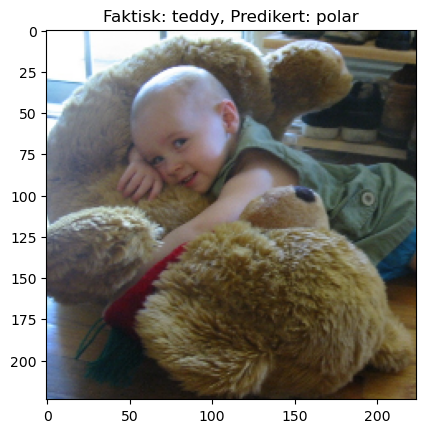

In [46]:
# KODEOPPGAVE 11

# Modell 2, bilder av teddybjørner klassifisert som isbjørn i modell 2:

# Din kode under her:
plot_predicted(y = y_test, y_pred = predictions_2, X=X_test, real_class=1, pred_class=0, 
               class_dict=class_dict, nr_pic=10)

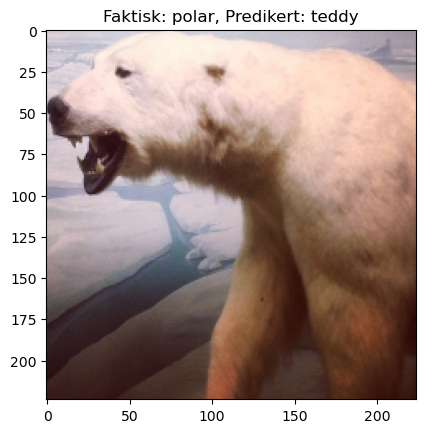

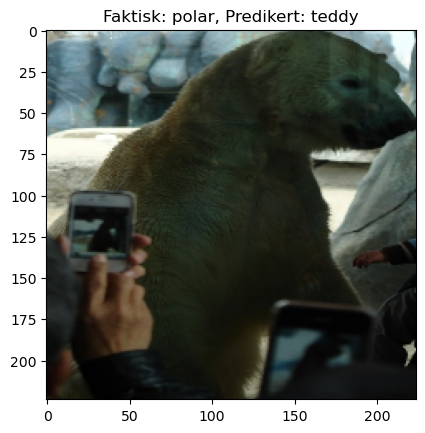

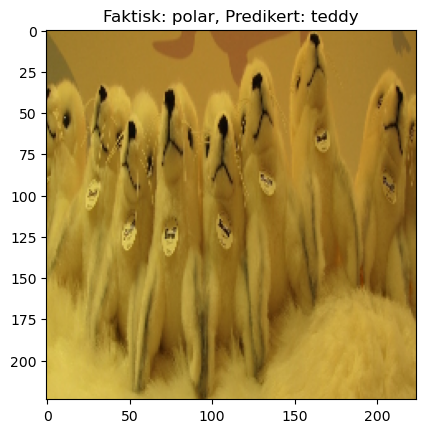

In [47]:
# KODEOPPGAVE 11

# Modell 2, bilder av isbjørner klassifisert som teddybjørn i modell 2:

# Din kode under her:
plot_predicted(y = y_test, y_pred = predictions_2, X=X_test, real_class=0, pred_class=1, 
               class_dict=class_dict, nr_pic=10)

In [48]:
# KODEOPPGAVE 11

# Modell 3, bilder av teddybjørner klassifisert som isbjørn i modell 3:

# Din kode under her:
plot_predicted(y = y_test, y_pred = predictions_3, X=X_test, real_class=1, pred_class=0, 
               class_dict=class_dict, nr_pic=10)

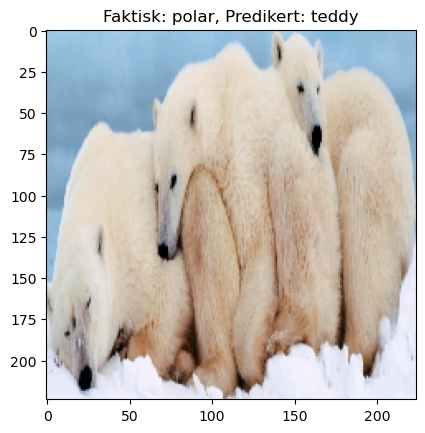

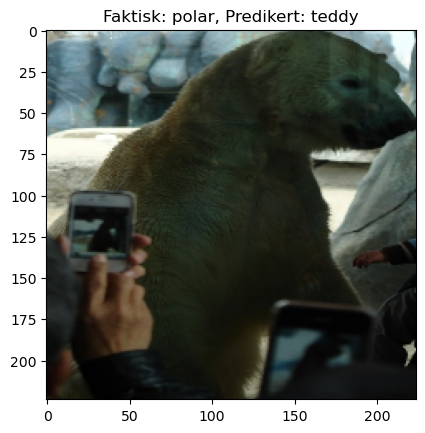

In [49]:
# KODEOPPGAVE 11

# Modell 3, bilder av isbjørner klassifisert som teddybjørn i modell 3:

# Din kode under her:
plot_predicted(y = y_test, y_pred = predictions_3, X=X_test, real_class=0, pred_class=1, 
               class_dict=class_dict, nr_pic=10)

_**Fritekstoppgave**:_

10. _Etter å ha predikert klassene til testbildene, og plottet dem som har blitt feilaktig predikert, kommenter hver av modellene separat: Hva kan du si om bildene som er feilklassifisert? Er noen av disse vanskelig å klassifisere for et menneske? Etter å ha sett på dette: Hvilken av modellene ville du helst ha brukt?_

**Svar:**

10. Modell 1 feilklassifiserer eksempler på teddybjørnbilder og tvetydige bilder
    Modell 3 har kun vansker med tvetydige bilder. Hvis andre bilder er feilklassifisert, sjekk om svaret gir mening med hensyn til dem.

## 8. Forklar resultatene ved hjelp av LIME:

LIME står for "Local Interpretable Model-agnostic Explanations", og hjelper med å forstå hvilke deler av et bilde som bidrar for eller mot en spesifikk prediksjon av et bilde, for eksempel for en klassifikasjon.

Stegene i LIME er som følger:
1. **LIME lager flere bilder basert på orignialbildet**. Originalbildet deles inn i superpixler (en sampling av flere pixler) og man genererer flere bilder (samples) hvor noen av disse superpixlene er synlige (resten blir sort). 
2. **Den trente modellen brukes til å predikere hvert sample generert i punkt 1.**
3. **Beregn vekter for hvert sample**. For bilder beregnes vekten som cosinus-distansen mellom det perturberte bilde og originalbildet. Jo mer likhet, dess større er vekten.
4. **En lineær regresjonsmodel tilpasses ved bruk av vektene fra punkt 3 og brukes til å finne de viktigste superpixlene**. Jo større koeffisient, desto viktigere er superpixelen.

Ved å bruke LIME, kan vi bestemme hvilke deler av bildet som er avgjørende for at modellen gir den prediksjonen (klassifiseringen) som den gjør.

For mer informasjon, sjekk: https://towardsdatascience.com/interpreting-image-classification-model-with-lime-1e7064a2f2e5

**Kodeoppgave 13: Forklar resultatene med LIME**:
   
Funksjonen `show_explanation()` som ligger i python-fila `exam_functions.py` kan brukes til å forklare hvilke deler av et bilde som bidrar **for eller imot** en prediksjon av den korrekte klassen til bildet.
Sett deg inn i argumentene som funksjonen trenger, og bruk funksjonen til å vise superpiksler for og imot korrekt label for bildet `X_test[1]` for `model_1` og `model_3`.

**Hint**: Du trenger å kalle `show_explanation()` to ganger for **hver modell** for å besvare oppgaven.

**NB**: For å besvare åpent spørsmål 8 i eksamensdokumentet må du plotte LIME-superpixler for dine modell-prediksjoner.

***Det åpne spørsmål 8 kan besvares ved hjelp av disse bilder.***

  0%|          | 0/500 [00:00<?, ?it/s]

1/1 [==============================] - 0s 52ms/step


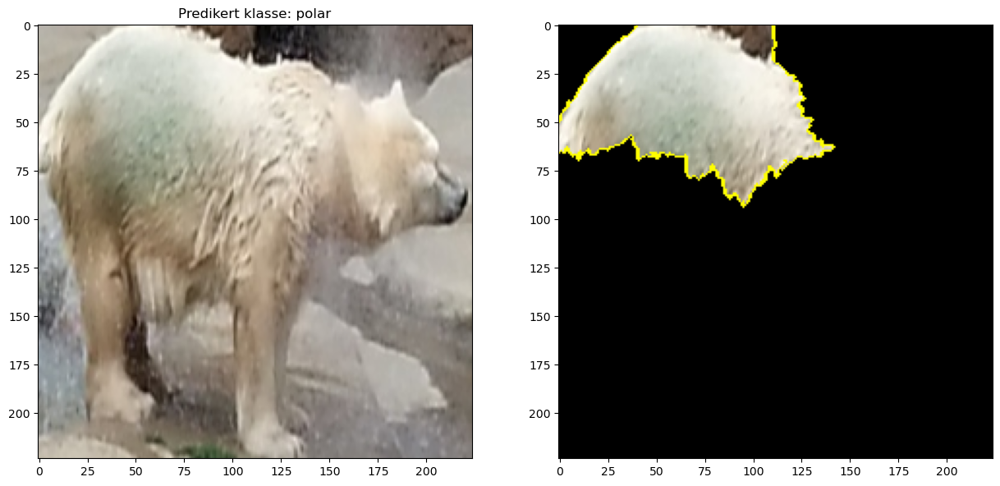

In [50]:
# KODEOPPGAVE 12

# Model 1: Hvilke deler bidrar til en prediksjon av den korrekte klassen?

# Din kode under her:
show_explanation(model=model_1, X=X_test, class_dict=class_dict, pic_ind=1, negative=False)

  0%|          | 0/500 [00:00<?, ?it/s]

1/1 [==============================] - 0s 44ms/step


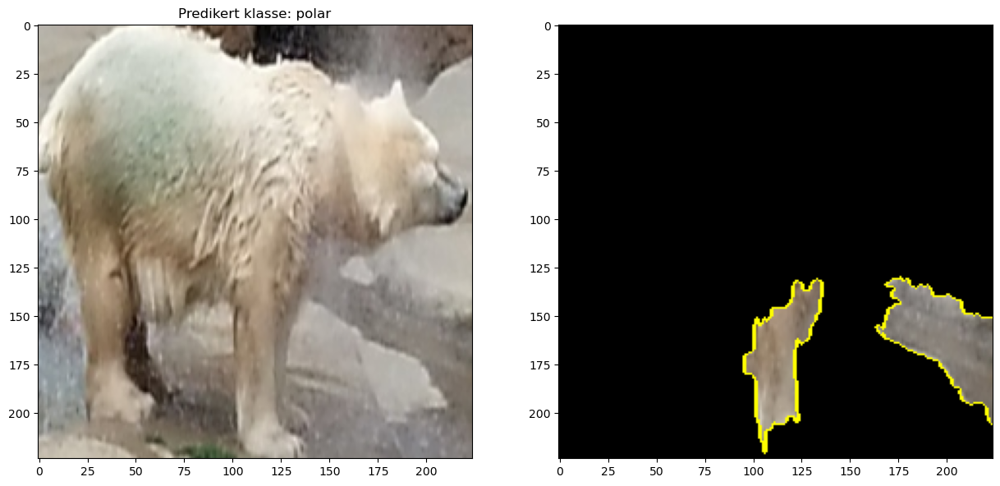

In [51]:
# KODEOPPGAVE 12

# Model 1: Hvilke deler bidrar imot en prediksjon av den korrekte klassen?

# Din kode under her:
show_explanation(model=model_1, X=X_test, class_dict=class_dict, pic_ind=1, negative=True)

  0%|          | 0/500 [00:00<?, ?it/s]

1/1 [==============================] - 0s 123ms/step


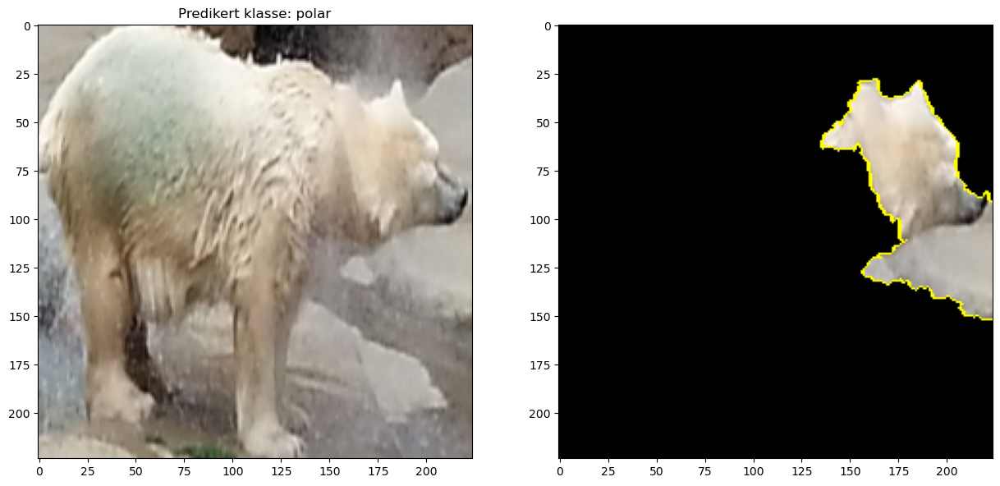

In [52]:
# KODEOPPGAVE 12

# Model 3: Hvilke deler bidrar til en prediksjon av den korrekte klassen?

# Din kode under her:
show_explanation(model=model_3, X=X_test, class_dict=class_dict, pic_ind=1, negative=False)

  0%|          | 0/500 [00:00<?, ?it/s]

1/1 [==============================] - 0s 96ms/step


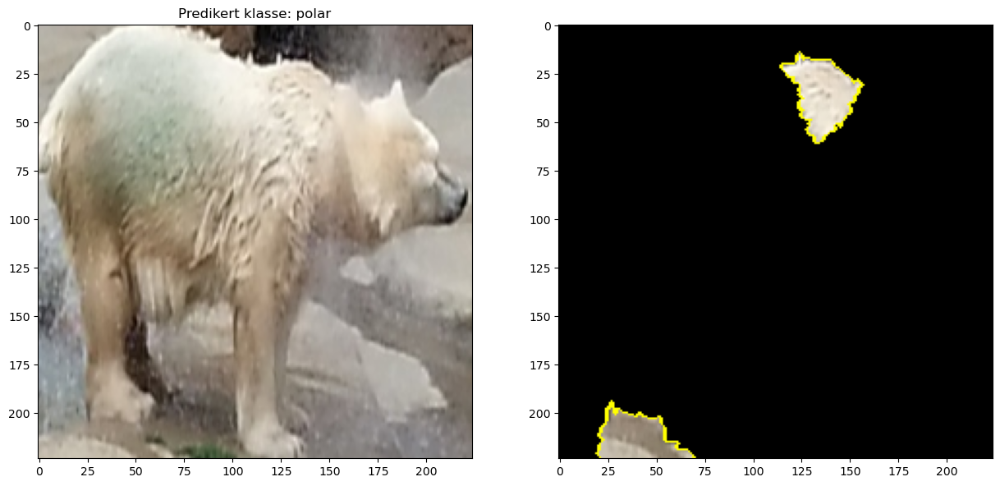

In [53]:
# KODEOPPGAVE 12

# Model 3: Hvilke deler bidrar imot en prediksjon av den korrekte klassen?

# Din kode under her:
show_explanation(model=model_3, X=X_test, class_dict=class_dict, pic_ind=1, negative=True)

## 9. Klyngeanalyse

**Kodeoppgave 13: Klyngeanalyse**

Bruk gjerne koden fra Module 4 for å løse denne kodeoppgaven.

Datasettet ClusterData.csv (ligger i mappen Data), består av 1000 datapunkter, hvor hvert datapunkt består av seks variabler.
Du skal benytte albue-metoden til å avgjøre hvor mange klynger som er passende for k-means klyngedannelse.

Tilleggsressurser:
* https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
* https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

In [54]:
#Last ned data:
data = pd.read_csv('Clusterdata.csv') 

C:\Users\geas001\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


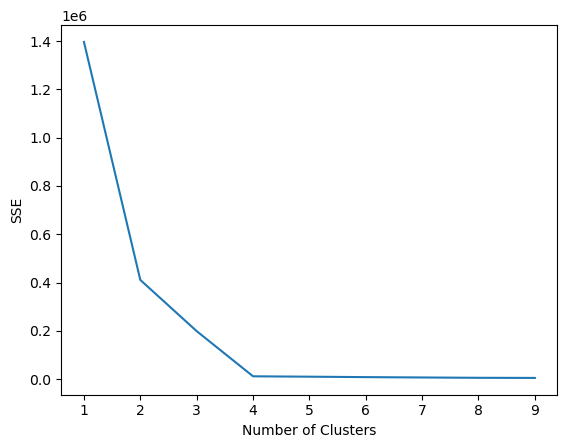

In [55]:
# KODEOPPGAVE 13

# Din kode under her:

kmeans_kwargs = {"init": "random","n_init": 10,"max_iter": 300}

sse = []
for k in range(1, 10):
    kmeans = KMeans(n_clusters=k, **kmeans_kwargs)
    kmeans.fit(data)
    sse.append(kmeans.inertia_)
    

plt.plot(range(1, 10), sse)
plt.xticks(range(1, 10))
plt.xlabel("Number of Clusters")
plt.ylabel("SSE")
plt.show()

_**Fritekstoppgave**:_

11. _Beskriv hva du finner for begge tilfellene og begge modellene._
    Bruk funksjonen show_explanation() fra exam_functions.py for å forklare hvilke deler av bildet bidrar «for» og hvilke deler bidrar «mot» å predikere riktig label for image X_test[1] for henholdsvis model_1 og model_3. Beskriv hva du finner for begge tilfellene og begge modellene.

**Svar:**

11. For modell 1 ser vi at både deler som taler «for» og «mot» at det er isbjørn inkluderer både bakgrunnen og deler av bjørnen.
    For modell 3 ser vi at deler av bildet som taler «for» isbjørn inkluderer deler av bjørnen, mens deler som taler «mot» inkluderer bakgrunnen. Hvis et annet svar er gitt, sjekk om det gir mening med hensyn til de angitte bildene.

**Nedenfor er ikke en del av innsendingsoppgave 2.**

**Kodeoppgave 14: Dimensjonalitetsreduksjon**

Bruk gjerne koden fra Module 4 for å løse denne kodeoppgaven.

Hvilken dimensjonalitetsreduksjonsteknikk kan du bruke for å visualisere klyngene? Bruk denne metoden og plott klyngene i **to** dimensjoner.

Tilleggsressurser:
* https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
* https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
* https://matplotlib.org/3.5.0/api/_as_gen/matplotlib.pyplot.scatter.html

Text(0, 0.5, 'PCA 2')

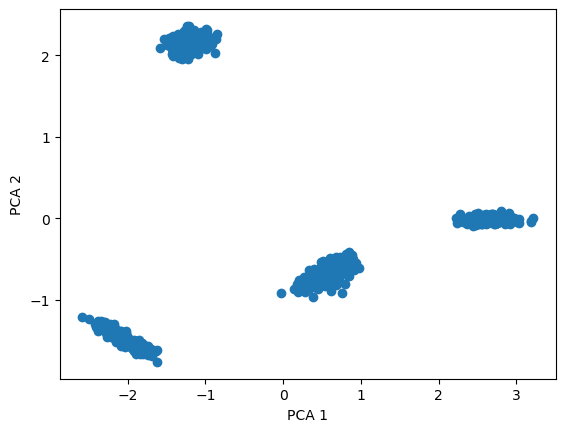

In [56]:
# KODEOPPGAVE 14

# Din kode under her:

scaler = preprocessing.StandardScaler().fit(data)
data_scaled = scaler.transform(data)
pca = PCA()
pca.fit(data_scaled)


data_pca = pd.DataFrame(pca.fit_transform(data_scaled))
fig = plt.figure()
ax = fig.add_subplot()
ax.scatter(data_pca[0], data_pca[1])
ax.set_xlabel('PCA 1')
ax.set_ylabel('PCA 2')

***Gå til eksamensheftet og les oppgave 10. Løs oppgaven med din kode.***